# 02 · Análise descritiva e exploratória

**Etapa II do roteiro:** estatística descritiva univariada, análise bivariada e matriz de correlação.

Os insights aparecem nas células **💡 Insight** logo após cada resultado e são consolidados no final do notebook (e em `reports/insights.md`).

> Pré-requisito: executar o notebook `01_contexto_e_limpeza.ipynb`, que gera a base limpa.

In [1]:
# ---------------------------------------------------------------
# Configuração do ambiente
# ---------------------------------------------------------------
# Localiza a raiz do projeto (pasta que contém "src/") para que os imports
# funcionem tanto rodando o notebook pelo Jupyter quanto pelo run_all.py.
import sys
from pathlib import Path

raiz = Path.cwd()
while not (raiz / "src").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import config
from src import limpeza, descritiva, inferencia, graficos

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
graficos.aplicar_estilo()

In [2]:
df = limpeza.carregar_dados_limpos()
taxa_geral = df["Attrition_bin"].mean() * 100
print(f"{len(df)} funcionários · {df['Attrition_bin'].sum()} saíram · taxa geral de saída = {taxa_geral:.1f}%")

1470 funcionários · 237 saíram · taxa geral de saída = 16.1%


## 1. Estatística descritiva univariada

### 1.1 Variáveis numéricas
Medidas pedidas no roteiro: **média, mediana, desvio padrão, IQR, assimetria, mínimo e máximo**.

Como ler a **assimetria**: ≈ 0 indica distribuição simétrica; > 0 indica cauda à direita (poucos valores muito altos puxam a média para cima); acima de 1, a assimetria é forte.

In [3]:
tab_num = descritiva.medidas_numericas(df, config.VARS_NUMERICAS)
descritiva.salvar_tabela(tab_num.round(2), "descritiva_numericas")
tab_num

,n,media,mediana,desvio_padrao,Q1,Q3,IQR,assimetria,minimo,maximo
variavel,,,,,,,,,,
Age,1470,36.92,36.00,9.14,30.00,43.00,13.00,0.41,18,60
MonthlyIncome,1470,"6,502.93","4,919.00","4,707.96","2,911.00","8,379.00","5,468.00",1.37,1009,19999
DistanceFromHome,1470,9.19,7.00,8.11,2.00,14.00,12.00,0.96,1,29
NumCompaniesWorked,1470,2.69,2.00,2.50,1.00,4.00,3.00,1.03,0,9
PercentSalaryHike,1470,15.21,14.00,3.66,12.00,18.00,6.00,0.82,11,25
TotalWorkingYears,1470,11.28,10.00,7.78,6.00,15.00,9.00,1.12,0,40
TrainingTimesLastYear,1470,2.80,3.00,1.29,2.00,3.00,1.00,0.55,0,6
YearsAtCompany,1470,7.01,5.00,6.13,3.00,9.00,6.00,1.76,0,40
YearsInCurrentRole,1470,4.23,3.00,3.62,2.00,7.00,5.00,0.92,0,18


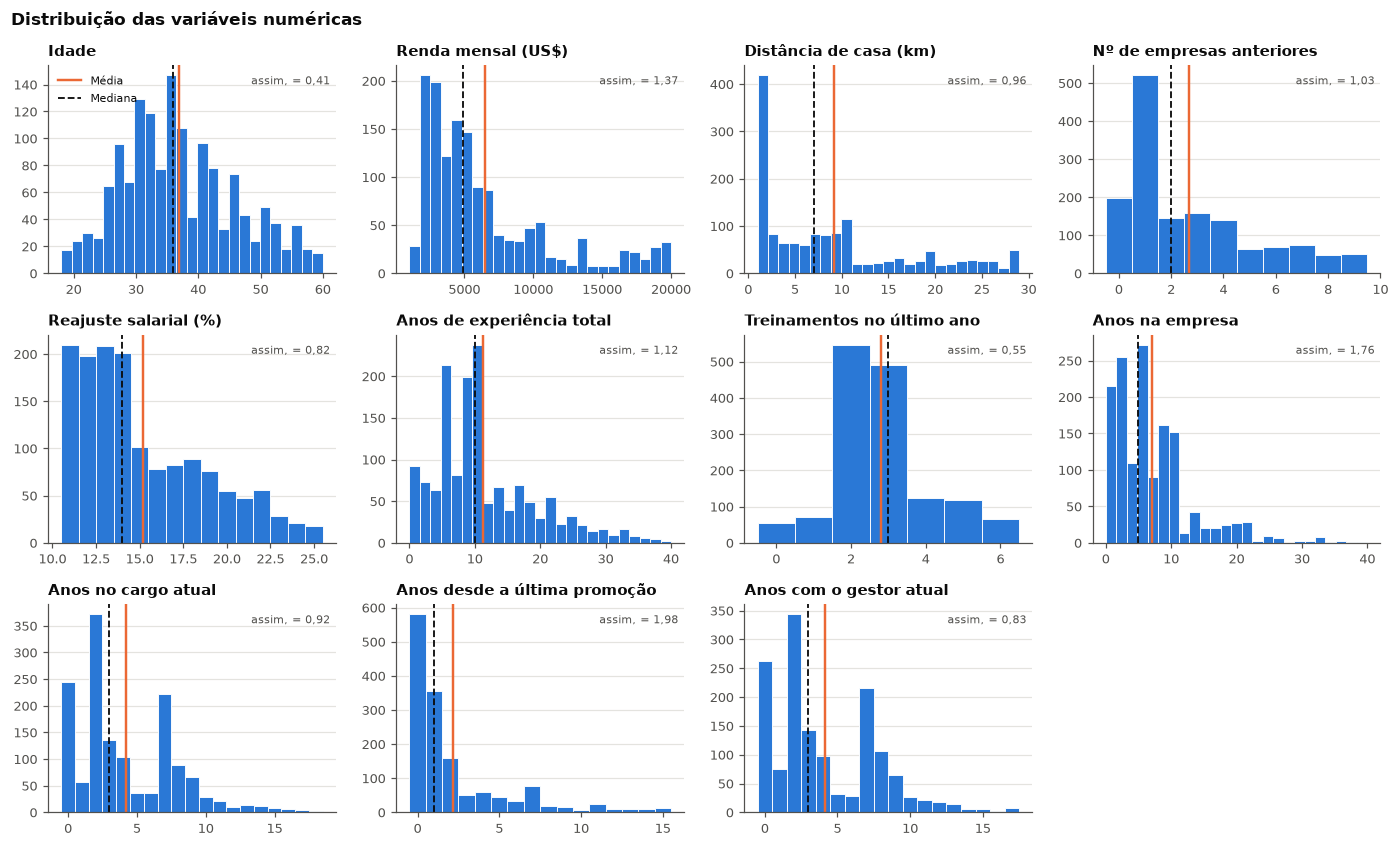

In [4]:
fig = graficos.grade_histogramas(df, config.VARS_NUMERICAS, ncols=4)
fig.suptitle("Distribuição das variáveis numéricas", x=0.01, ha="left", fontsize=11, weight="bold", y=1.02)
graficos.salvar(fig, "fig03_histogramas")
plt.show()

💡 **Insight — perfil numérico**
- **Idade** é quase simétrica (média 36,9 e mediana 36 anos): uma força de trabalho majoritariamente entre 30 e 43 anos (Q1–Q3).
- **Renda mensal** tem forte assimetria (1,37): a média (US$ 6.503) fica bem acima da mediana (US$ 4.919). O salário "típico" é a mediana.
- **Variáveis de tempo** (anos na empresa, desde a última promoção) também têm cauda à direita: a maioria tem pouco tempo de casa, e poucos têm décadas.
- **Anos desde a última promoção** tem mediana 1, mas a cauda chega a 15 anos: há um grupo pequeno de funcionários "estagnados".

### 1.2 Variáveis categóricas
Frequência **absoluta** (contagem) e **relativa** (%) de cada categoria.

In [5]:
cols_freq = config.VARS_CATEGORICAS
tab_freq = descritiva.frequencias(df, cols_freq)
descritiva.salvar_tabela(tab_freq, "frequencias_categoricas", index=False)
# Exibe algumas variáveis-chave (a tabela completa está no CSV)
tab_freq[tab_freq["variavel"].isin(["Attrition", "Department", "OverTime", "JobInvolvement",
                                    "EnvironmentSatisfaction", "PerformanceRating"])]

,variavel,categoria,freq_absoluta,freq_relativa_pct
0,Attrition,No,1233,83.88
1,Attrition,Yes,237,16.12
2,Department,Research & Development,961,65.37
3,Department,Sales,446,30.34
4,Department,Human Resources,63,4.29
25,OverTime,No,1054,71.70
26,OverTime,Yes,416,28.30
35,EnvironmentSatisfaction,1,284,19.32
36,EnvironmentSatisfaction,2,287,19.52
37,EnvironmentSatisfaction,3,453,30.82


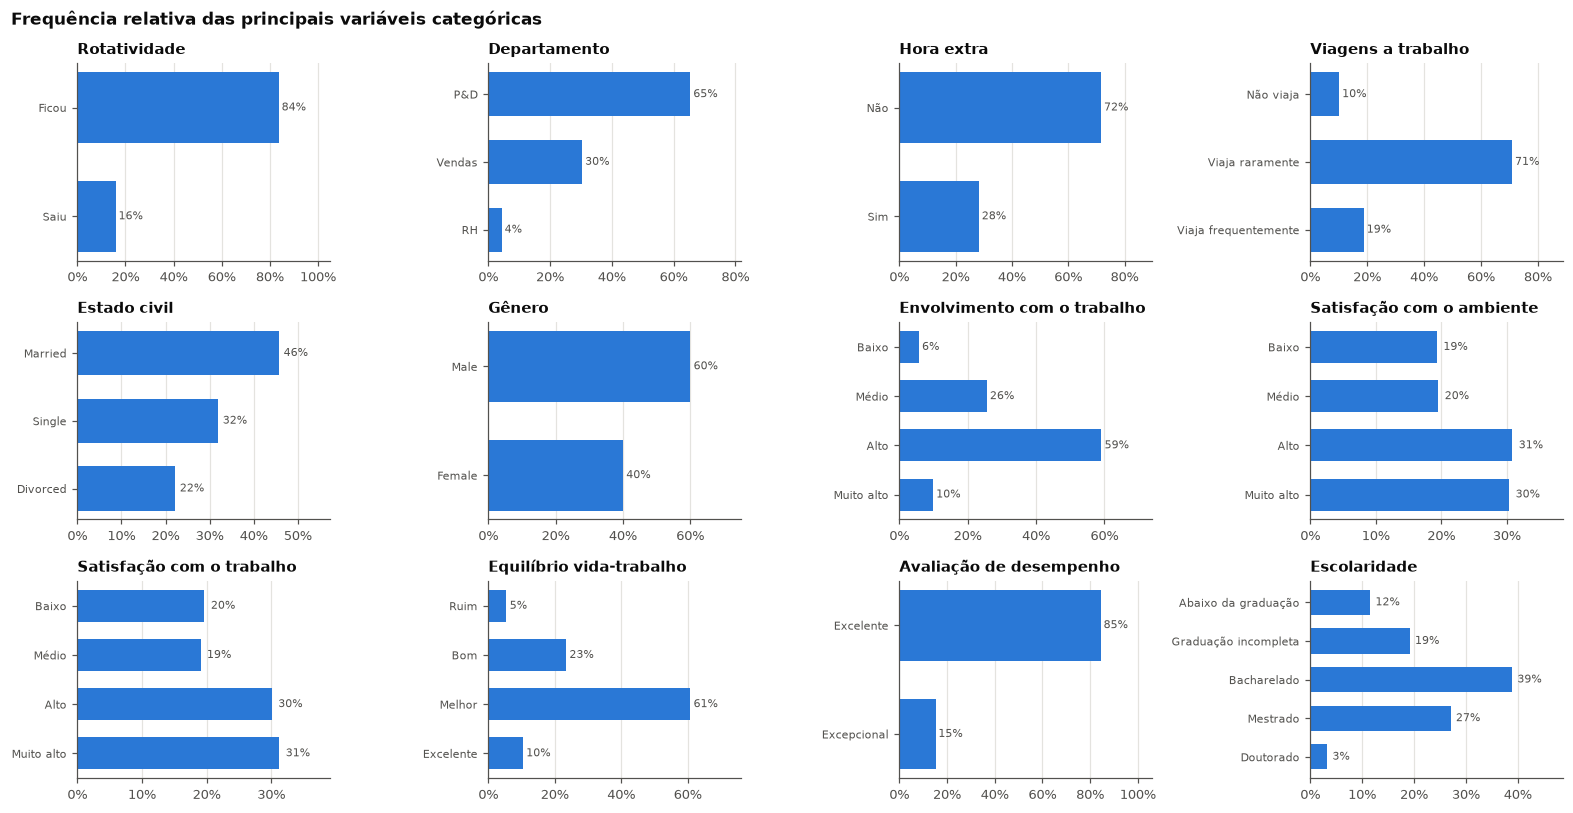

In [6]:
cols_graf = ["Status", "Departamento", "HoraExtra", "Viagens", "MaritalStatus", "Gender",
             "JobInvolvement_rot", "EnvironmentSatisfaction_rot", "JobSatisfaction_rot",
             "WorkLifeBalance_rot", "PerformanceRating_rot", "Education_rot"]
rotulos = {"Status": "Rotatividade", "Departamento": "Departamento", "HoraExtra": "Hora extra",
           "Viagens": "Viagens a trabalho", "MaritalStatus": "Estado civil", "Gender": "Gênero"}
fig = graficos.grade_barras(df, cols_graf, ncols=4, rotulos=rotulos)
fig.suptitle("Frequência relativa das principais variáveis categóricas", x=0.01, ha="left",
             fontsize=11, weight="bold", y=1.02)
graficos.salvar(fig, "fig04_frequencias_categoricas")
plt.show()

💡 **Insight — perfil categórico**
- **16,1% dos funcionários saíram** (237 de 1.470): a variável-alvo é desbalanceada, mas tem casos suficientes para os testes.
- **P&D concentra 65%** do quadro, Vendas 30% e RH apenas 4% (n = 63). Isso explica por que o IC do RH será largo.
- **28% fazem hora extra.**
- **`PerformanceRating` só tem duas notas**: 85% "Excelente" (3) e 15% "Excepcional" (4). Ninguém tem nota 1 ou 2, uma possível **inflação de avaliações**.
- Cerca de **19–20% dos funcionários** relatam satisfação **baixa** com o ambiente ou com o trabalho.

## 2. Análise bivariada orientada pelas perguntas de negócio
Em todos os gráficos de taxa: **barras de erro = IC 95% (Wilson)**, **linha tracejada = taxa geral (16,1%)** e **laranja = grupo com maior taxa**.

### Q1 · Rotatividade por departamento e cargo

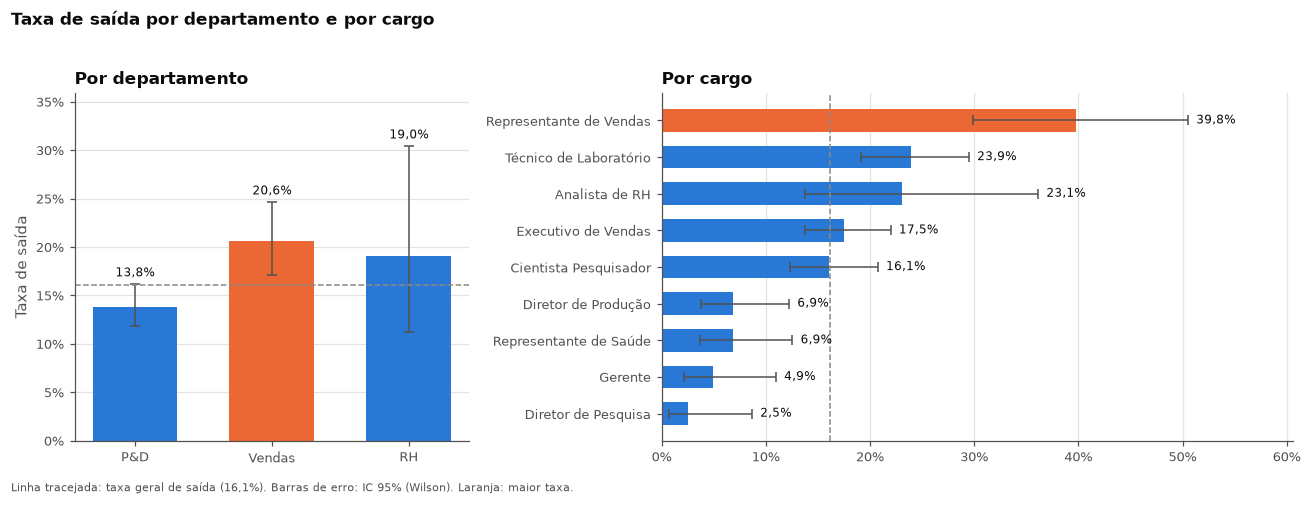

,categoria,n,saidas,taxa_pct,ic_inf_pct,ic_sup_pct,grupo
0,P&D,961,133,13.84,11.80,16.17,Departamento
1,Vendas,446,92,20.63,17.13,24.63,Departamento
2,RH,63,12,19.05,11.25,30.41,Departamento
2,Diretor de Pesquisa,80,2,2.50,0.69,8.66,Cargo
5,Gerente,102,5,4.90,2.11,10.97,Cargo
6,Representante de Saúde,131,9,6.87,3.66,12.54,Cargo
3,Diretor de Produção,145,10,6.90,3.79,12.23,Cargo
1,Cientista Pesquisador,292,47,16.10,12.33,20.75,Cargo
4,Executivo de Vendas,326,57,17.48,13.75,21.98,Cargo
0,Analista de RH,52,12,23.08,13.72,36.13,Cargo


In [7]:
t_dep = descritiva.taxa_saida_por_grupo(df, "Departamento")
t_cargo = descritiva.taxa_saida_por_grupo(df, "Cargo").sort_values("taxa_pct")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
graficos.barras_taxa(axes[0], t_dep, "Departamento", taxa_geral, "Por departamento")
graficos.barras_taxa(axes[1], t_cargo, "Cargo", taxa_geral, "Por cargo", horizontal=True)
fig.suptitle("Taxa de saída por departamento e por cargo", x=0.01, ha="left", fontsize=11, weight="bold", y=1.02)
graficos.nota_taxa_geral(fig, taxa_geral)
fig.tight_layout()
graficos.salvar(fig, "fig05_q1_departamento_cargo")
plt.show()
pd.concat([t_dep.assign(grupo="Departamento").rename(columns={"Departamento": "categoria"}),
           t_cargo.assign(grupo="Cargo").rename(columns={"Cargo": "categoria"})])

💡 **Insight Q1**
- **Vendas tem a maior taxa** (20,6%), seguida de RH (19,0%) e P&D (13,8%). O IC do RH é largo (11%–30%) porque o grupo é pequeno.
- No nível de **cargo** a diferença é muito maior: **Representantes de Vendas perdem 39,8%** dos funcionários, quase 2,5× a média. Técnicos de Laboratório (23,9%) e Analistas de RH (23,1%) vêm em seguida.
- Cargos de gestão (Diretor de Pesquisa 2,5%, Gerente 4,9%) quase não perdem pessoas.
- ➜ **O problema está mais concentrado em cargos de entrada do que em departamentos inteiros.**

### Q2 · Salário: quem sai ganha menos?

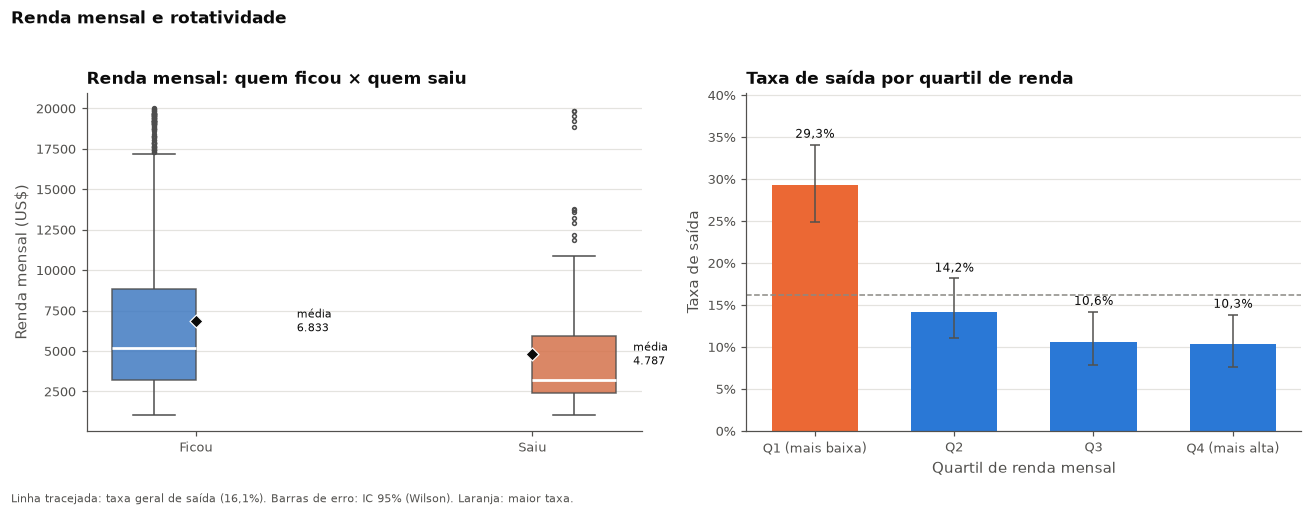

,FaixaSalarial,n,saidas,taxa_pct,ic_inf_pct,ic_sup_pct
0,Q1 (mais baixa),369,108,29.27,24.86,34.11
1,Q2,366,52,14.21,11.00,18.16
2,Q3,367,39,10.63,7.87,14.20
3,Q4 (mais alta),368,38,10.33,7.62,13.86


In [8]:
t_faixa = descritiva.taxa_saida_por_grupo(df, "FaixaSalarial")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
graficos.boxplot_por_status(axes[0], df, "MonthlyIncome", "Renda mensal: quem ficou × quem saiu")
graficos.barras_taxa(axes[1], t_faixa, "FaixaSalarial", taxa_geral, "Taxa de saída por quartil de renda")
axes[1].set_xlabel("Quartil de renda mensal")
fig.suptitle("Renda mensal e rotatividade", x=0.01, ha="left", fontsize=11, weight="bold", y=1.02)
graficos.nota_taxa_geral(fig, taxa_geral)
fig.tight_layout()
graficos.salvar(fig, "fig06_q2_renda")
plt.show()
t_faixa

In [9]:
# Renda mediana por nível de cargo: a diferença salarial se mantém dentro do mesmo nível?
renda_nivel = (df.pivot_table(index="JobLevel", columns="Status", values="MonthlyIncome",
                              aggfunc="median", observed=True)
                 .join(df.groupby(["JobLevel", "Status"], observed=True).size().unstack().add_prefix("n_")))
descritiva.salvar_tabela(renda_nivel, "renda_mediana_por_nivel_status")
renda_nivel

Status,Ficou,Saiu,n_Ficou,n_Saiu
JobLevel,,,,
1,"2,719.00","2,437.00",400,143
2,"5,334.50","5,346.00",482,52
3,"9,982.50","9,887.00",186,32
4,"16,307.00","13,194.00",101,5
5,"19,199.50","19,545.00",64,5


💡 **Insight Q2**
- **Quem saiu tem renda mediana de US$ 3.202, contra US$ 5.204 de quem ficou** (cerca de 38% menor).
- A taxa de saída no **quartil de menor renda é 29,3%**, quase **3× a dos quartis mais altos** (≈ 10%).
- ⚠️ **Cuidado com a interpretação:** renda acompanha o nível do cargo e a experiência (Spearman com `JobLevel` ≈ 0,92 e com experiência total ≈ 0,71). **Dentro do mesmo nível, a renda mediana de quem sai e de quem fica é quase igual** (nível 1: US$ 2.437 × 2.719; nível 2: US$ 5.346 × 5.335; nível 3: US$ 9.887 × 9.983).
- **60% das saídas (143 de 237) estão no nível 1.** A diferença salarial entre os grupos vem principalmente de **quem sai estar concentrado em cargos de entrada**, e não de pessoas ganhando menos que seus pares. ➜ O salário baixo é, em boa parte, um **marcador de início de carreira**.

### Q3 · Envolvimento e ambiente de trabalho

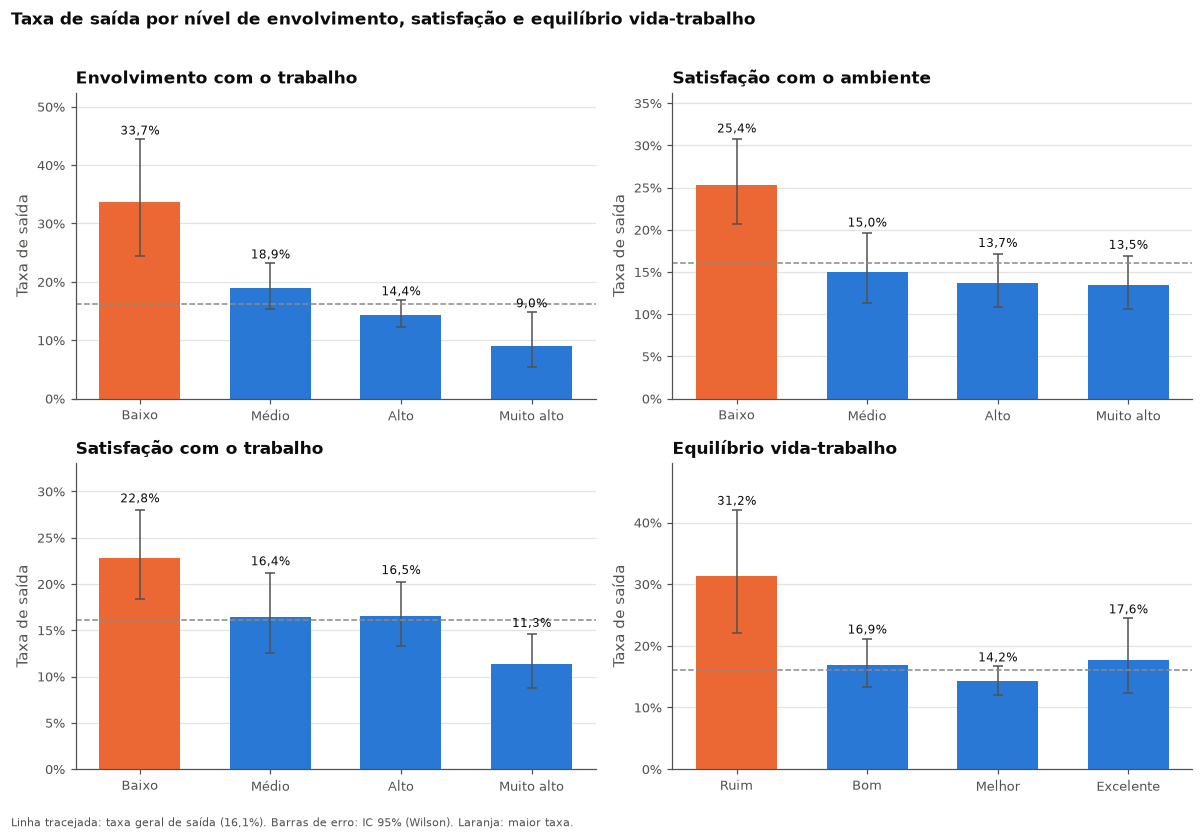

,fator,nivel,n,saidas,taxa_pct,ic_inf_pct,ic_sup_pct
0,Envolvimento com o trabalho,Baixo,83,28,33.73,24.48,44.42
1,Envolvimento com o trabalho,Médio,375,71,18.93,15.29,23.21
2,Envolvimento com o trabalho,Alto,868,125,14.40,12.22,16.89
3,Envolvimento com o trabalho,Muito alto,144,13,9.03,5.35,14.83
0,Satisfação com o ambiente,Baixo,284,72,25.35,20.64,30.72
1,Satisfação com o ambiente,Médio,287,43,14.98,11.32,19.57
2,Satisfação com o ambiente,Alto,453,62,13.69,10.83,17.16
3,Satisfação com o ambiente,Muito alto,446,60,13.45,10.60,16.93
0,Satisfação com o trabalho,Baixo,289,66,22.84,18.37,28.01
1,Satisfação com o trabalho,Médio,280,46,16.43,12.55,21.22


In [10]:
fatores = {
    "JobInvolvement_rot": "Envolvimento com o trabalho",
    "EnvironmentSatisfaction_rot": "Satisfação com o ambiente",
    "JobSatisfaction_rot": "Satisfação com o trabalho",
    "WorkLifeBalance_rot": "Equilíbrio vida-trabalho",
}
fig, axes = plt.subplots(2, 2, figsize=(11, 7.2))
tabs_q3 = []
for ax, (col, titulo) in zip(axes.flat, fatores.items()):
    t = descritiva.taxa_saida_por_grupo(df, col)
    graficos.barras_taxa(ax, t, col, taxa_geral, titulo)
    tabs_q3.append(t.rename(columns={col: "nivel"}).assign(fator=titulo))
fig.suptitle("Taxa de saída por nível de envolvimento, satisfação e equilíbrio vida-trabalho",
             x=0.01, ha="left", fontsize=11, weight="bold", y=1.01)
graficos.nota_taxa_geral(fig, taxa_geral)
fig.tight_layout()
graficos.salvar(fig, "fig07_q3_envolvimento_ambiente")
plt.show()
pd.concat(tabs_q3)[["fator", "nivel", "n", "saidas", "taxa_pct", "ic_inf_pct", "ic_sup_pct"]]

💡 **Insight Q3**
- **Envolvimento é o fator com o gradiente mais claro:** a taxa cai de **33,7% (baixo)** para **9,0% (muito alto)**, uma redução de quase 4×.
- **Ambiente com satisfação baixa:** 25,4% de saída, contra ≈ 13,5–15% nos demais níveis. O salto acontece entre "Baixo" e "Médio", o que indica um **efeito de limiar**: basta sair do nível baixo.
- **Equilíbrio vida-trabalho "Ruim":** 31,2%, quase o dobro dos demais níveis.
- **Satisfação com o trabalho:** cai de 22,8% (baixa) para 11,3% (muito alta).
- ➜ Em todos os fatores, **o nível mais baixo concentra o risco**. Isso sugere priorizar quem está na pior condição, e não tentar melhorar todos os níveis igualmente.

### Q4 · Hora extra

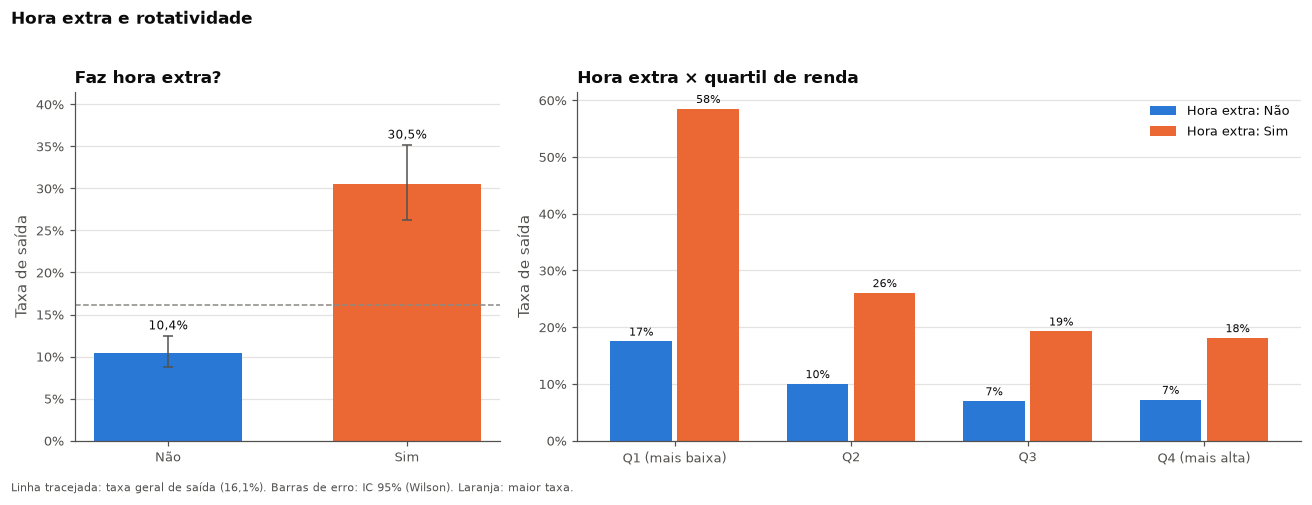

,HoraExtra,n,saidas,taxa_pct,ic_inf_pct,ic_sup_pct
0,Não,1054,110,10.44,8.73,12.43
1,Sim,416,127,30.53,26.30,35.12


HoraExtra,Não,Sim
FaixaSalarial,,
Q1 (mais baixa),17.49,58.49
Q2,10.00,26.04
Q3,6.98,19.27
Q4 (mais alta),7.22,18.10


In [11]:
t_he = descritiva.taxa_saida_por_grupo(df, "HoraExtra")
# Taxa de saída com e sem hora extra dentro de cada quartil de renda
he_faixa = (df.groupby(["FaixaSalarial", "HoraExtra"], observed=True)["Attrition_bin"]
              .mean().mul(100).unstack())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.7]})
graficos.barras_taxa(axes[0], t_he, "HoraExtra", taxa_geral, "Faz hora extra?")
x = np.arange(len(he_faixa))
larg = 0.38
for i, (grupo, cor) in enumerate([("Não", config.COR_FICOU), ("Sim", config.COR_SAIU)]):
    barras = axes[1].bar(x + (i - 0.5) * larg, he_faixa[grupo], width=larg - 0.03, color=cor,
                         label=f"Hora extra: {grupo}")
    axes[1].bar_label(barras, fmt="%.0f%%", fontsize=7.5, padding=2, color=config.COR_TEXTO)
axes[1].set_xticks(x, he_faixa.index.astype(str))
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(decimals=0))
axes[1].set_title("Hora extra × quartil de renda")
axes[1].legend(loc="upper right")
axes[1].set_ylabel("Taxa de saída")
fig.suptitle("Hora extra e rotatividade", x=0.01, ha="left", fontsize=11, weight="bold", y=1.02)
graficos.nota_taxa_geral(fig, taxa_geral)
fig.tight_layout()
graficos.salvar(fig, "fig08_q4_hora_extra")
plt.show()
display(t_he)
he_faixa

💡 **Insight Q4**
- **Quem faz hora extra sai 3× mais: 30,5% contra 10,4%.** É a maior diferença entre todas as variáveis analisadas.
- O efeito **aparece em todos os quartis de renda**, e é extremo no quartil mais baixo, onde mais da metade de quem faz hora extra saiu. Hora extra e salário baixo **somam risco**.
- ➜ Hora extra é uma **variável sob controle direto da gestão**, o que a torna a alavanca de ação mais imediata.

### Q5 · Desempenho, envolvimento e reajuste salarial

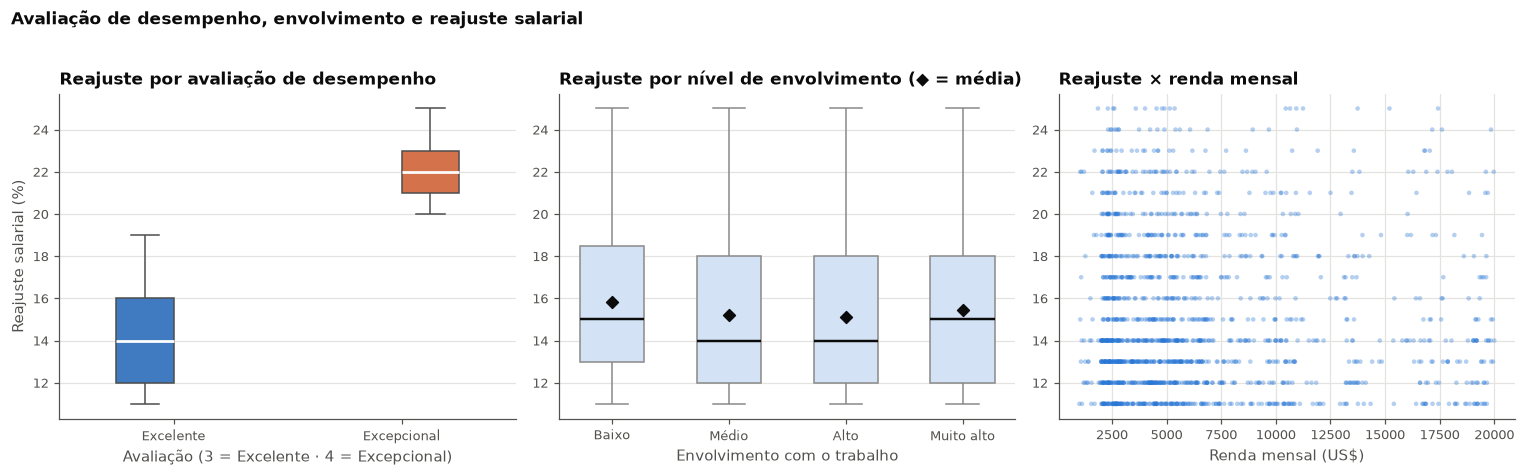

,count,mean,min,max
PerformanceRating_rot,,,,
Excelente,1244,14.00,11,19
Excepcional,226,21.85,20,25


,PerformanceRating_rot,n,saidas,taxa_pct,ic_inf_pct,ic_sup_pct
0,Excelente,1244,200,16.08,14.14,18.22
1,Excepcional,226,37,16.37,12.12,21.75


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
cor_nota = {"Excelente": config.COR_FICOU, "Excepcional": config.COR_SAIU}
import seaborn as sns
sns.boxplot(data=df, x="PerformanceRating_rot", y="PercentSalaryHike", hue="PerformanceRating_rot",
            palette=cor_nota, width=0.5, ax=axes[0], legend=False, linewidth=1,
            medianprops=dict(color="white", lw=1.8))
axes[0].set_title("Reajuste por avaliação de desempenho")
axes[0].set_xlabel("Avaliação (3 = Excelente · 4 = Excepcional)")
axes[0].set_ylabel("Reajuste salarial (%)")

sns.boxplot(data=df, x="JobInvolvement_rot", y="PercentSalaryHike", color="#cde2fb", width=0.55,
            ax=axes[1], linewidth=1, medianprops=dict(color=config.COR_TEXTO, lw=1.6))
medias = df.groupby("JobInvolvement_rot", observed=True)["PercentSalaryHike"].mean()
axes[1].scatter(range(len(medias)), medias.values, marker="D", color=config.COR_TEXTO, s=30, zorder=5,
                label="média")
axes[1].set_title("Reajuste por nível de envolvimento (◆ = média)")
axes[1].set_xlabel("Envolvimento com o trabalho")
axes[1].set_ylabel("")

axes[2].scatter(df["MonthlyIncome"], df["PercentSalaryHike"], s=9, alpha=0.35, color=config.COR_FICOU,
                edgecolor="none")
axes[2].set_title("Reajuste × renda mensal")
axes[2].set_xlabel("Renda mensal (US$)")
axes[2].set_ylabel("")
axes[2].grid(axis="x")
fig.suptitle("Avaliação de desempenho, envolvimento e reajuste salarial", x=0.01, ha="left",
             fontsize=11, weight="bold", y=1.02)
fig.tight_layout()
graficos.salvar(fig, "fig09_q5_desempenho_reajuste")
plt.show()

tab_q5 = df.groupby("PerformanceRating_rot", observed=True)["PercentSalaryHike"].agg(["count", "mean", "min", "max"])
display(tab_q5)
display(descritiva.taxa_saida_por_grupo(df, "PerformanceRating_rot"))

💡 **Insight Q5**
- **O reajuste é determinado pela nota:** toda nota 3 recebeu entre 11% e 19%, e toda nota 4 recebeu entre 20% e 25%. As faixas **não se sobrepõem**, o que indica uma **regra fixa** (nota 4 ⇔ reajuste ≥ 20%).
- O **nível de envolvimento não muda o reajuste médio** (≈ 15% em todos os níveis), e **renda e reajuste não têm relação visível**.
- A **taxa de saída é praticamente igual nas duas notas** (16,1% × 16,4%): **a avaliação de desempenho não diferencia quem sai de quem fica**.
- ➜ A política de reconhecimento **premia a nota, mas ignora o envolvimento**, que é justamente o fator associado à saída (Q3).

## 3. Matriz de correlação
A matriz usa **Spearman** como principal (baseada em postos), porque muitas variáveis são assimétricas ou ordinais (escalas 1–4). A matriz de **Pearson** também é salva para comparação.

`Attrition_bin` e `OverTime_bin` (0/1) entram na matriz. A correlação de uma variável 0/1 com uma numérica equivale à correlação ponto-bisserial.

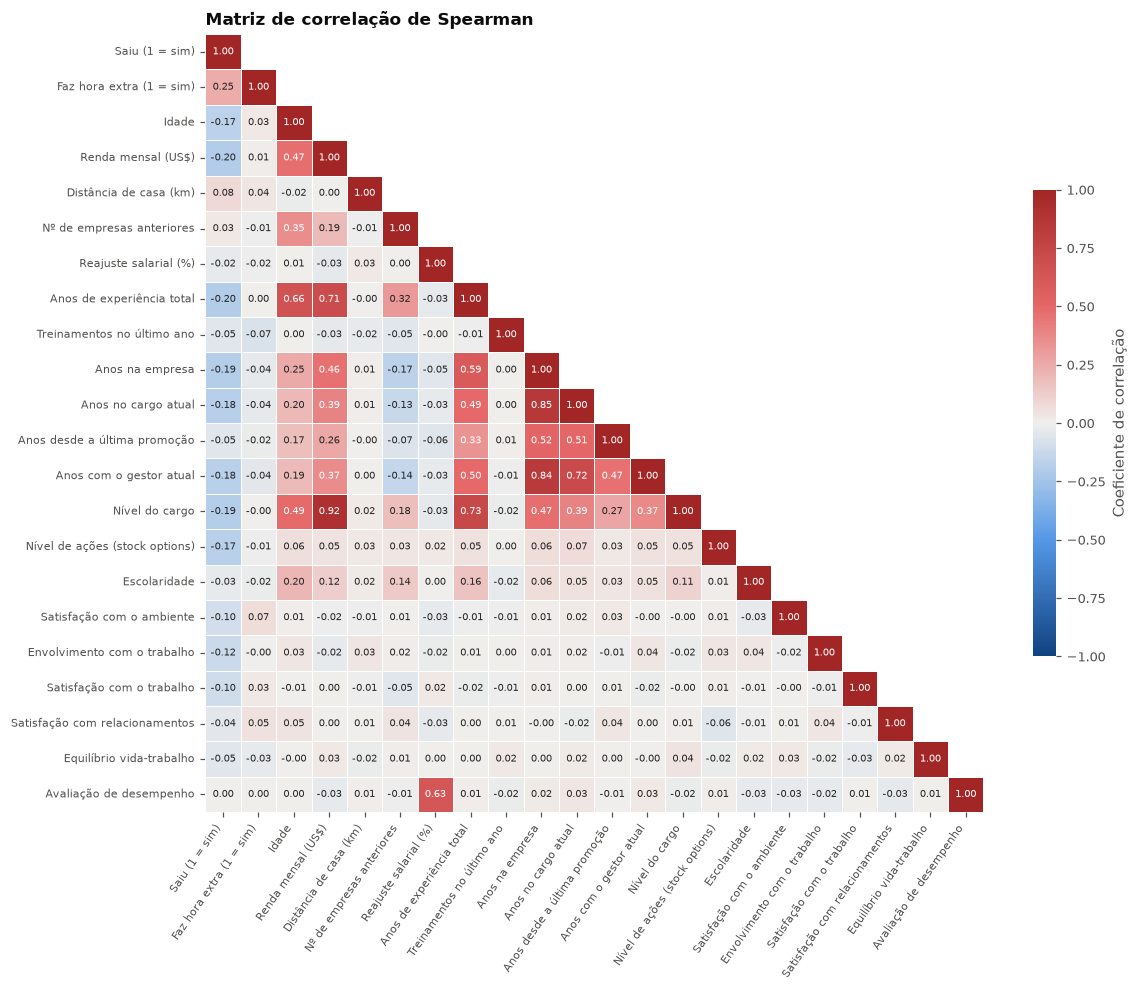

In [13]:
cols_corr = (["Attrition_bin", "OverTime_bin"] + config.VARS_NUMERICAS +
             ["JobLevel", "StockOptionLevel", "Education", "EnvironmentSatisfaction",
              "JobInvolvement", "JobSatisfaction", "RelationshipSatisfaction",
              "WorkLifeBalance", "PerformanceRating"])
corr_s = descritiva.matriz_correlacao(df, cols_corr, "spearman")
corr_p = descritiva.matriz_correlacao(df, cols_corr, "pearson")
descritiva.salvar_tabela(corr_s.round(3), "correlacao_spearman")
descritiva.salvar_tabela(corr_p.round(3), "correlacao_pearson")

fig = graficos.mapa_correlacao(corr_s, "Matriz de correlação de Spearman")
graficos.salvar(fig, "fig10_matriz_correlacao")
plt.show()

In [14]:
corr_alvo = descritiva.correlacoes_com_alvo(df, [c for c in cols_corr if c != "Attrition_bin"])
corr_alvo.index = [config.NOMES_PT.get(c, c) for c in corr_alvo.index]
descritiva.salvar_tabela(corr_alvo.round(3), "correlacao_com_saida")
corr_alvo.round(3)

,pearson,spearman
Anos de experiência total,-0.17,-0.20
Renda mensal (US$),-0.16,-0.20
Anos na empresa,-0.13,-0.19
Nível do cargo,-0.17,-0.19
Anos no cargo atual,-0.16,-0.18
Anos com o gestor atual,-0.16,-0.17
Nível de ações (stock options),-0.14,-0.17
Idade,-0.16,-0.17
Envolvimento com o trabalho,-0.13,-0.12
Satisfação com o trabalho,-0.10,-0.10


💡 **Insight — correlações**
- **Com a saída (Attrition):** a correlação positiva mais forte é com **hora extra** (+0,25). As negativas mais fortes são com **nível do cargo, renda, experiência total, anos no cargo e idade** (≈ −0,17 a −0,20). Quem sai é **mais jovem, mais júnior e ganha menos**.
- Todas as correlações com a saída são **fracas individualmente** (|ρ| < 0,3): **a rotatividade é multifatorial** e nenhum fator isolado a explica.
- **Entre as explicativas:** renda, nível do cargo e experiência total formam um bloco muito correlacionado (ρ entre 0,71 e 0,92), assim como as variáveis de tempo (anos na empresa, no cargo, com o gestor). Elas medem, em boa parte, a mesma coisa: **senioridade**.
- `PercentSalaryHike` × `PerformanceRating`: ρ ≈ 0,63 (Pearson ≈ 0,77), reflexo da regra de reajuste vista na Q5.
- As escalas de satisfação **não se correlacionam entre si** (|ρ| < 0,05): ambiente, trabalho e vida-trabalho são **dimensões independentes**, e cada uma precisa de ação própria.

## 4. Perfil complementar de quem sai

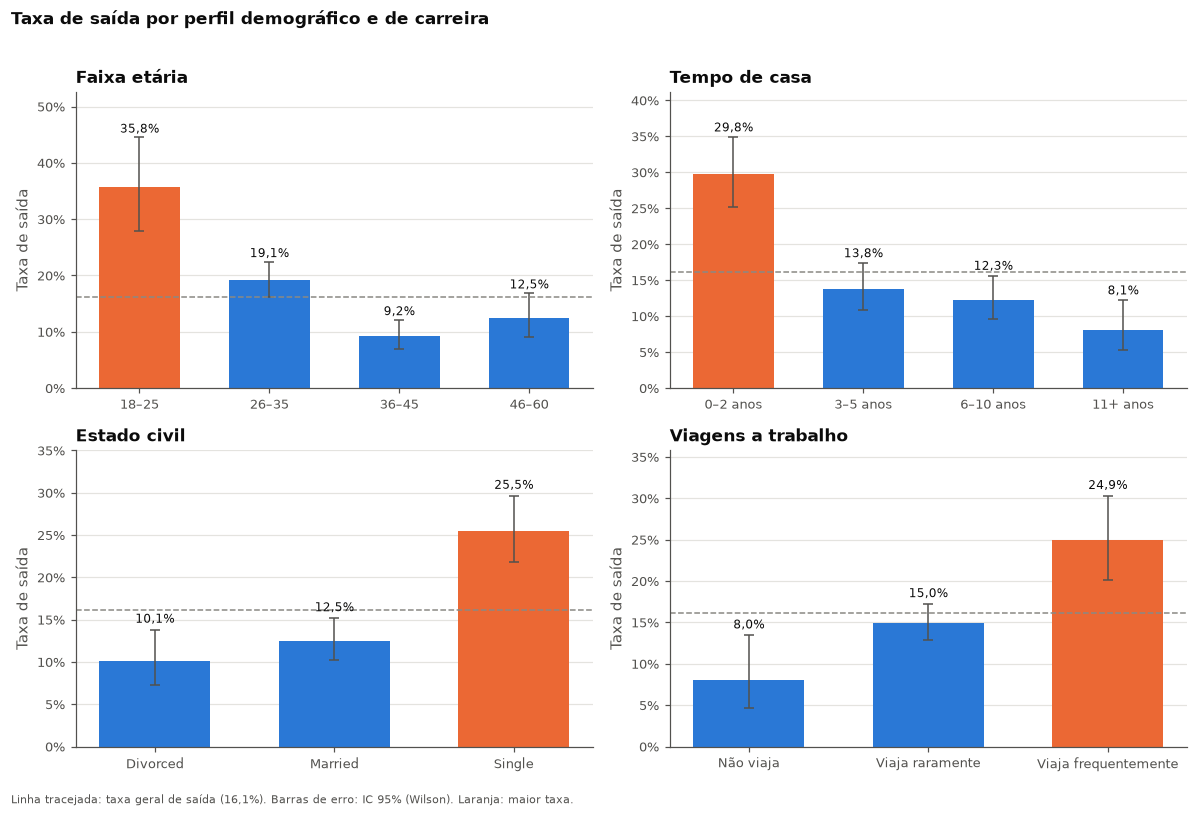

,categoria,n,saidas,taxa_pct,ic_inf_pct,ic_sup_pct,variavel
0,18–25,123,44,35.77,27.85,44.56,Faixa etária
1,26–35,606,116,19.14,16.21,22.46,Faixa etária
2,36–45,468,43,9.19,6.89,12.15,Faixa etária
3,46–60,273,34,12.45,9.05,16.90,Faixa etária
0,0–2 anos,342,102,29.82,25.22,34.88,Tempo de casa
1,3–5 anos,434,60,13.82,10.89,17.39,Tempo de casa
2,6–10 anos,448,55,12.28,9.55,15.64,Tempo de casa
3,11+ anos,246,20,8.13,5.32,12.22,Tempo de casa
0,Divorced,327,33,10.09,7.28,13.83,Estado civil
1,Married,673,84,12.48,10.20,15.19,Estado civil


In [15]:
perfil = {"FaixaEtaria": "Faixa etária", "FaixaTempoCasa": "Tempo de casa",
          "MaritalStatus": "Estado civil", "Viagens": "Viagens a trabalho"}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
tabs_perfil = []
for ax, (col, titulo) in zip(axes.flat, perfil.items()):
    t = descritiva.taxa_saida_por_grupo(df, col)
    graficos.barras_taxa(ax, t, col, taxa_geral, titulo)
    tabs_perfil.append(t.rename(columns={col: "categoria"}).assign(variavel=titulo))
fig.suptitle("Taxa de saída por perfil demográfico e de carreira", x=0.01, ha="left",
             fontsize=11, weight="bold", y=1.01)
graficos.nota_taxa_geral(fig, taxa_geral)
fig.tight_layout()
graficos.salvar(fig, "fig11_perfil_complementar")
plt.show()

# Tabela única com todas as taxas por grupo (alimenta o relatório)
grupos = ["Departamento", "Cargo", "FaixaSalarial", "HoraExtra", "JobInvolvement_rot",
          "EnvironmentSatisfaction_rot", "JobSatisfaction_rot", "WorkLifeBalance_rot",
          "PerformanceRating_rot", "FaixaEtaria", "FaixaTempoCasa", "MaritalStatus", "Viagens",
          "JobLevel", "StockOptionLevel"]
todas = pd.concat([descritiva.taxa_saida_por_grupo(df, g).rename(columns={g: "categoria"}).assign(variavel=g)
                   for g in grupos])[["variavel", "categoria", "n", "saidas", "taxa_pct", "ic_inf_pct", "ic_sup_pct"]]
descritiva.salvar_tabela(todas.round(2), "taxas_saida_por_grupo", index=False)
pd.concat(tabs_perfil)

💡 **Insight — perfil**
- **Jovens de 18–25 anos saem 35,8%**, e **funcionários com até 2 anos de casa saem 29,8%**: **o risco está concentrado no início da jornada**.
- **Solteiros** (25,5%) saem 2× mais que casados (12,5%) e divorciados (10,1%).
- **Quem viaja com frequência** sai 24,9%, contra 8,0% de quem não viaja.

In [16]:
# Comparação de médias e medianas entre quem ficou e quem saiu (tabela de apoio)
comp = descritiva.comparar_grupos(df, config.VARS_NUMERICAS)
descritiva.salvar_tabela(comp.round(2), "comparacao_ficou_saiu")
comp.round(1)

Status                            Ficou     Saiu
variavel                medida                  
Age                     mean      37.60    33.60
                        median    36.00    32.00
MonthlyIncome           mean   6,832.70 4,787.10
                        median 5,204.00 3,202.00
DistanceFromHome        mean       8.90    10.60
                        median     7.00     9.00
NumCompaniesWorked      mean       2.60     2.90
                        median     2.00     1.00
PercentSalaryHike       mean      15.20    15.10
                        median    14.00    14.00
TotalWorkingYears       mean      11.90     8.20
                        median    10.00     7.00
TrainingTimesLastYear   mean       2.80     2.60
                        median     3.00     2.00
YearsAtCompany          mean       7.40     5.10
                        median     6.00     3.00
YearsInCurrentRole      mean       4.50     2.90
                        median     3.00     2.00
YearsSinceLastPromotion mean       2.20     1.90
                        median     1.00     1.00
YearsWithCurrManager    mean       4.40     2.90
                        median     3.00     2.00

## 5. Insights consolidados (Etapa II)
1. **Taxa geral de saída: 16,1%** (237 de 1.470).
2. **Hora extra** é a variável com a maior diferença: **30,5% × 10,4%** (≈ 3×).
3. **Renda baixa:** o quartil inferior tem **29,3%** de saída, ≈ 3× os quartis superiores. Mas renda se confunde com **senioridade**: dentro do mesmo nível de cargo, quem sai e quem fica ganham quase o mesmo.
4. **Envolvimento baixo** (33,7%), **ambiente com satisfação baixa** (25,4%) e **vida-trabalho ruim** (31,2%) concentram o risco no **nível mais baixo** de cada escala.
5. **Cargo pesa mais que departamento:** Representantes de Vendas chegam a **39,8%** de saída.
6. **Início de carreira** (jovens, nível 1, até 2 anos de casa, solteiros) é o perfil de maior risco.
7. **Desempenho não diferencia quem sai**, e o reajuste segue uma **regra fixa atrelada à nota**, sem relação com envolvimento.

➜ O notebook **03** verifica, com testes de hipóteses e intervalos de confiança, se essas diferenças são estatisticamente significativas ou se podem ser fruto do acaso.